In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
dados_mnist = tf.keras.datasets.mnist
(imagens_treino, rotulos_treino), (imagens_teste, rotulos_teste) = dados_mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
imagens_treino = imagens_treino / 255.0
imagens_teste = imagens_teste / 255.0
rotulos_treino_one_hot = tf.one_hot(rotulos_treino, 10)
rotulos_teste_one_hot = tf.one_hot(rotulos_teste, 10)

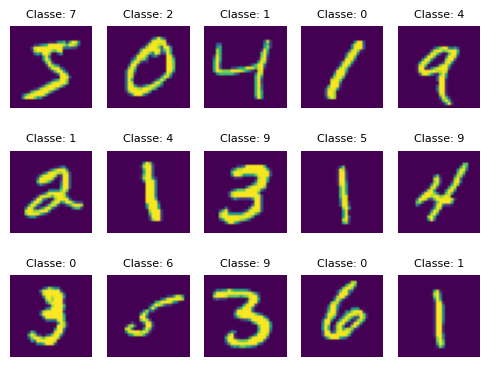

In [ ]:
plt.figure(figsize=(5 ,4))
for indice in range(15):
  plt.subplot(3, 5, indice + 1)
  plt.imshow(imagens_treino[indice])
  plt.title(f'Classe: {tf.argmax(rotulos_teste_one_hot[indice])}', fontsize=8)
  plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
modelo_mlp = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [ ]:
opt = tf.keras.optimizers.RMSprop(learning_rate=0.01) #método para cálculo do Gradiente (Adam)
modelo_mlp.compile(optimizer=opt, loss='mse', metrics=['mse'])

historico_treinamento = modelo_mlp.fit(
    imagens_treino,
    rotulos_treino_one_hot,
    epochs=5,
    validation_split=0.1
)

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0130 - mse: 0.0130 - val_loss: 0.0097 - val_mse: 0.0097
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - loss: 0.0080 - mse: 0.0080 - val_loss: 0.0068 - val_mse: 0.0068
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0070 - mse: 0.0070 - val_loss: 0.0101 - val_mse: 0.0101
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0062 - mse: 0.0062 - val_loss: 0.0053 - val_mse: 0.0053
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0058 - mse: 0.0058 - val_loss: 0.0063 - val_mse: 0.0063


<function matplotlib.pyplot.show(close=None, block=None)>

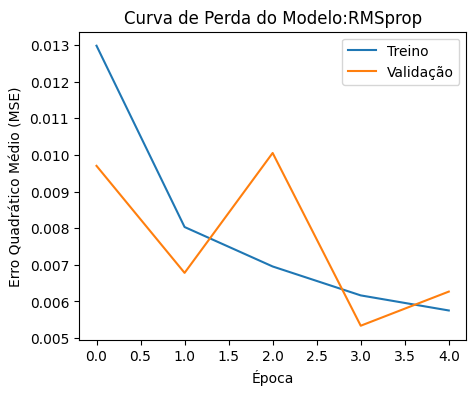

In [ ]:
plt.figure(figsize=(5, 4))
plt.plot(historico_treinamento.history['loss'])
plt.plot(historico_treinamento.history['val_loss'])
plt.title('Curva de Perda do Modelo:RMSprop')
plt.ylabel('Erro Quadrático Médio (MSE)')
plt.xlabel('Época')
plt.legend(['Treino', 'Validação'])
plt.show

In [ ]:
modelo_mlp.save('meu_modelo_mnist.keras')

In [ ]:
modelo_carregado = tf.keras.models.load_model('meu_modelo_mnist.keras')

indice_amostra = 67
amostra = imagens_teste[indice_amostra]
amostra_batch = np.expand_dims(amostra, axis=0)
previsao = modelo_carregado.predict(amostra_batch)
classe_predita = np.argmax(previsao)
classe_real = rotulos_teste[indice_amostra]
print(f'Predição: {classe_predita} | Real: {classe_real}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
Predição: 4 | Real: 4


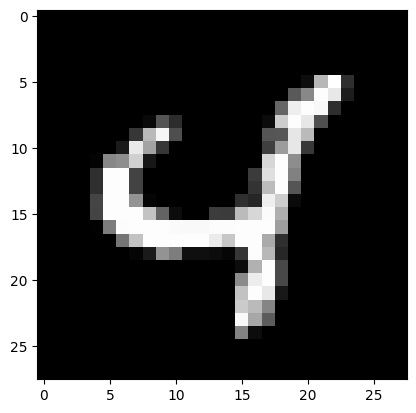

In [ ]:
plt.imshow(amostra, cmap='gray')